# Exploratory Data Analysis (EDA) - ข้อมูลจริง (WESAD Dataset)
ใน Notebook นี้ เราจะทำการโหลดข้อมูลของจริงจากโฟลเดอร์ S2 (Subject 2) มาวิเคราะห์กันครับ!
เราจะเน้นไปที่เซ็นเซอร์หน้าอก (RespiBAN) เพราะเป็นไปตามที่คุณต้องการในแผนงานครับ

In [4]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. โหลดข้อมูลของ Subject 2 (S2)
ไฟล์ข้อมูลถูกเก็บในรูปแบบ Pickle (.pkl) เราจะทำการโหลดและดูโครงสร้างของมันครับ

In [5]:
file_path = 'data/WESAD/S2/S2.pkl'

with open(file_path, 'rb') as f:
    # Dataset นี้ถูกเซฟด้วย Python 2 จึงต้องใช้ encoding='latin1'
    s2_data = pickle.load(f, encoding='latin1')

print("Keys in S2 data:", s2_data.keys())
print("Keys in RespiBAN (Chest) signal:", s2_data['signal']['chest'].keys())

labels = s2_data['label']
chest_eda = s2_data['signal']['chest']['EDA'].flatten()
chest_temp = s2_data['signal']['chest']['Temp'].flatten()

print(f"Total data points: {len(labels)}")


Keys in S2 data: dict_keys(['signal', 'label', 'subject'])
Keys in RespiBAN (Chest) signal: dict_keys(['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'])
Total data points: 4255300


## 2. พล็อตกราฟสัญญาณ EDA และ Temperature
เนื่องจากข้อมูลมีความถี่ 700 Hz (วินาทีละ 700 จุด) รวมแล้วมีหลายล้านจุด เพื่อไม่ให้กราฟช้าเกินไป เราจะดึงมาแสดงผลแค่ทุกๆ 1 วินาที (Downsample) ครับ

* **Label 1 (สีเขียว)** = สภาวะปกติ (Baseline)
* **Label 2 (สีแดง)** = สภาวะเครียด (Stress)

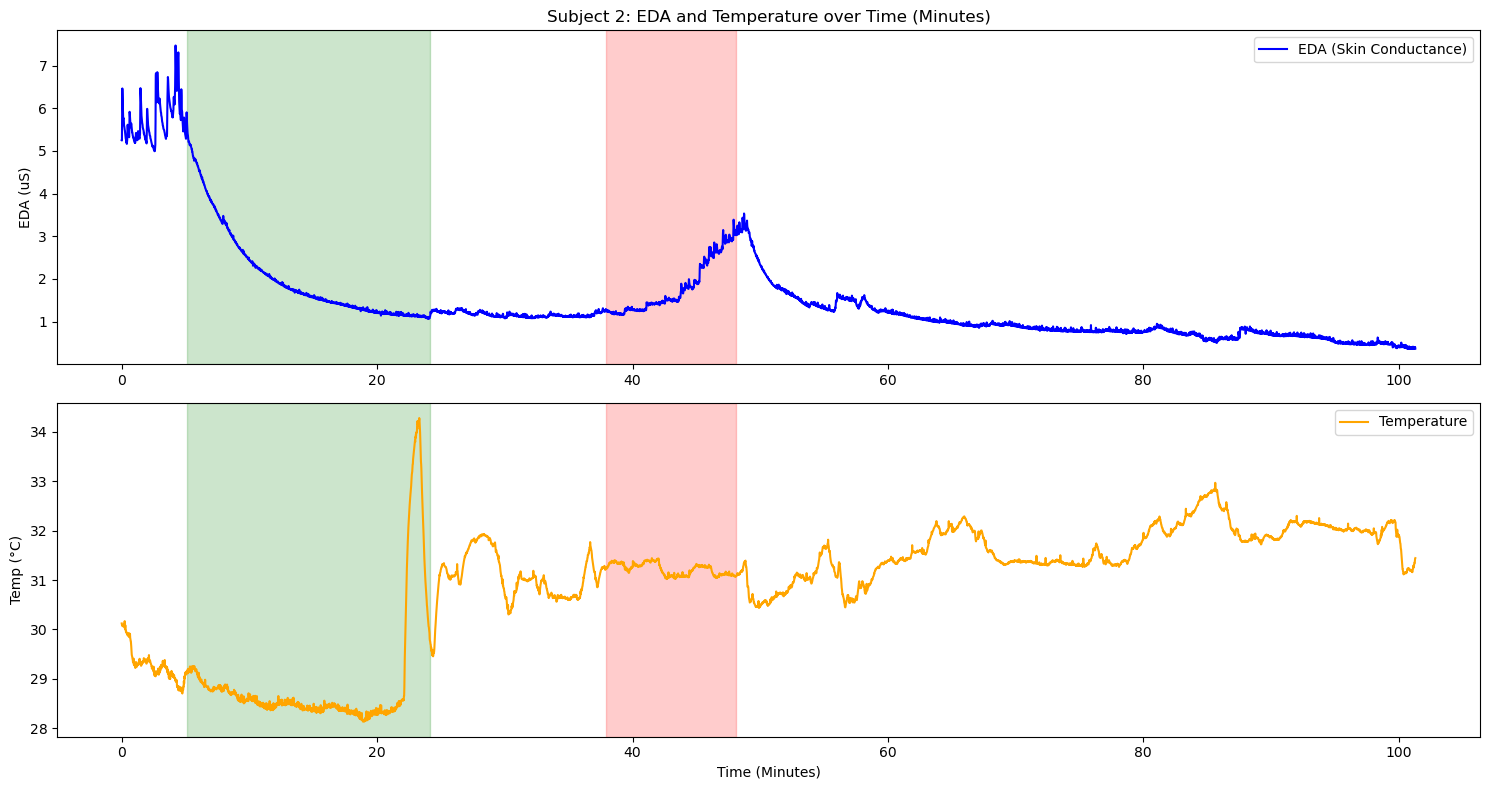

In [6]:
# ลดขนาดข้อมูลโดยดึงมา 1 จุด ทุกๆ 700 จุด (1 Hz)
fs = 700
downsample_rate = fs

time_axis = np.arange(0, len(labels)) / fs

time_ds = time_axis[::downsample_rate]
eda_ds = chest_eda[::downsample_rate]
temp_ds = chest_temp[::downsample_rate]
labels_ds = labels[::downsample_rate]

plt.figure(figsize=(15, 8))

# พล็อตกราฟ EDA
ax1 = plt.subplot(2, 1, 1)
plt.plot(time_ds / 60, eda_ds, color='blue', label='EDA (Skin Conductance)')
plt.ylabel('EDA (uS)')
plt.title('Subject 2: EDA and Temperature over Time (Minutes)')

# สร้างฟังก์ชันช่วยไฮไลท์พื้นหลัง
def highlight_background(ax, time_arr, label_arr):
    # หาจุดเปลี่ยนสถานะ
    changes = np.where(np.diff(label_arr) != 0)[0]
    start_idx = 0
    for idx in changes:
        end_idx = idx
        val = label_arr[start_idx]
        if val == 2:
            ax.axvspan(time_arr[start_idx]/60, time_arr[end_idx]/60, color='red', alpha=0.2)
        elif val == 1:
            ax.axvspan(time_arr[start_idx]/60, time_arr[end_idx]/60, color='green', alpha=0.2)
        start_idx = end_idx + 1
    # ไฮไลท์บล็อกสุดท้าย
    val = label_arr[start_idx]
    if val == 2:
        ax.axvspan(time_arr[start_idx]/60, time_arr[-1]/60, color='red', alpha=0.2)
    elif val == 1:
        ax.axvspan(time_arr[start_idx]/60, time_arr[-1]/60, color='green', alpha=0.2)

highlight_background(ax1, time_ds, labels_ds)
plt.legend(loc='upper right')

# พล็อตกราฟ Temperature
ax2 = plt.subplot(2, 1, 2)
plt.plot(time_ds / 60, temp_ds, color='orange', label='Temperature')
plt.xlabel('Time (Minutes)')
plt.ylabel('Temp (°C)')

highlight_background(ax2, time_ds, labels_ds)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()